In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path = "../data/outlier_deal_for_nan_exp2.csv"
df = pd.read_csv(path)

cols = ["Affect Level", "Alertness Level"]

# 1. 参照点ごとの有効回答数(NaN は除く)
print(df.groupby("ref_subblock")[cols].count())

# 2. 記述統計
print(df.groupby("ref_subblock")[cols].agg(["count", "mean", "std", "median"]).round(2))

# 3. 値ごとの選択数(10刻みにまとめた表)
print(df[cols].describe())                    # 値の範囲を先に確認(0〜100か)
bins = np.arange(0, 101, 10)
for col in cols:
    binned = pd.cut(df[col], bins=bins, include_lowest=True)
    print(f"\n{col}")
    print(pd.crosstab(binned, df["ref_subblock"]))

              Affect Level  Alertness Level
ref_subblock                               
0                     1733             1733
1                     1729             1729
2                     1734             1734
3                     1724             1724
4                     1731             1731
             Affect Level                      Alertness Level                \
                    count   mean    std median           count   mean    std   
ref_subblock                                                                   
0                    1733  53.26  20.71   52.0            1733  46.42  20.11   
1                    1729  53.75  20.23   51.0            1729  46.08  19.67   
2                    1734  54.52  21.77   53.0            1734  47.78  21.47   
3                    1724  54.27  20.95   53.0            1724  47.32  20.82   
4                    1731  54.24  20.69   53.0            1731  46.76  20.05   

                     
             median  
ref_sub

#### 参照点別 感情評価 記述統計量

ref_point        1     2     3     4     5
ref_subblock                              
0             1760     0     0     0     0
1                0  1760     0     0     0
2                0     0     0     0  1760
3                0     0     0  1760     0
4                0     0  1760     0     0


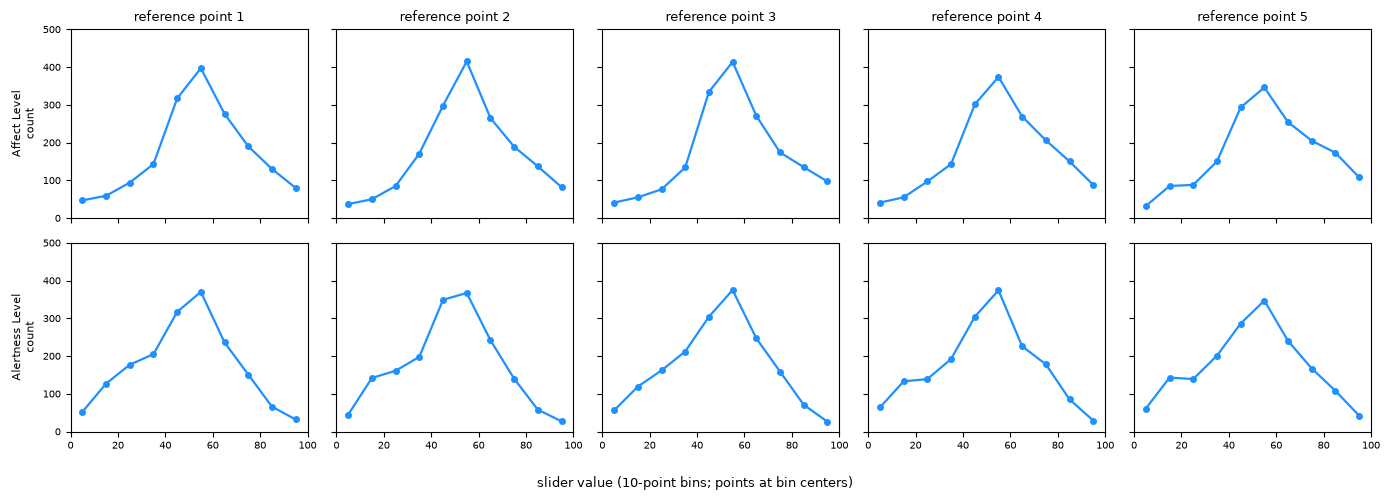

In [37]:
# ref_subblock → 参照点の番号(全員・全ブロックで同じ対応と仮定)
ref_map = {0: 1, 1: 2, 2: 5, 3: 4, 4: 3}
df["ref_point"] = df["ref_subblock"].map(ref_map)
print(pd.crosstab(df["ref_subblock"], df["ref_point"]))     # 対応の確認

points = [1, 2, 3, 4, 5]                                    # 並べたい順
cols = ["Affect Level", "Alertness Level"]
BIN_WIDTH = 10
bins = np.arange(0, 100 + BIN_WIDTH, BIN_WIDTH)
mid = bins[:-1] + BIN_WIDTH / 2

fig, axes = plt.subplots(len(cols), 5, figsize=(14, 5), sharex=True, sharey=True)
for r, col in enumerate(cols):
    for c, p in enumerate(points):
        ax = axes[r, c]
        x = df.loc[df["ref_point"] == p, col].dropna()
        h, _ = np.histogram(x, bins=bins)
        ax.plot(mid, h, marker="o", ms=4, lw=1.6, color="#1e90ff")
        if r == 0:
            ax.set_title(f"reference point {p}", fontsize=9)
        if c == 0:
            ax.set_ylabel(f"{col}\ncount", fontsize=8)
        ax.set_xticks(np.arange(0, 101, 20))
        ax.tick_params(labelsize=7)

axes[0, 0].set_ylim(0, 500)
axes[0, 0].set_xlim(0, 100)
fig.supxlabel(f"slider value ({BIN_WIDTH}-point bins; points at bin centers)", fontsize=9)
plt.tight_layout()
plt.show()

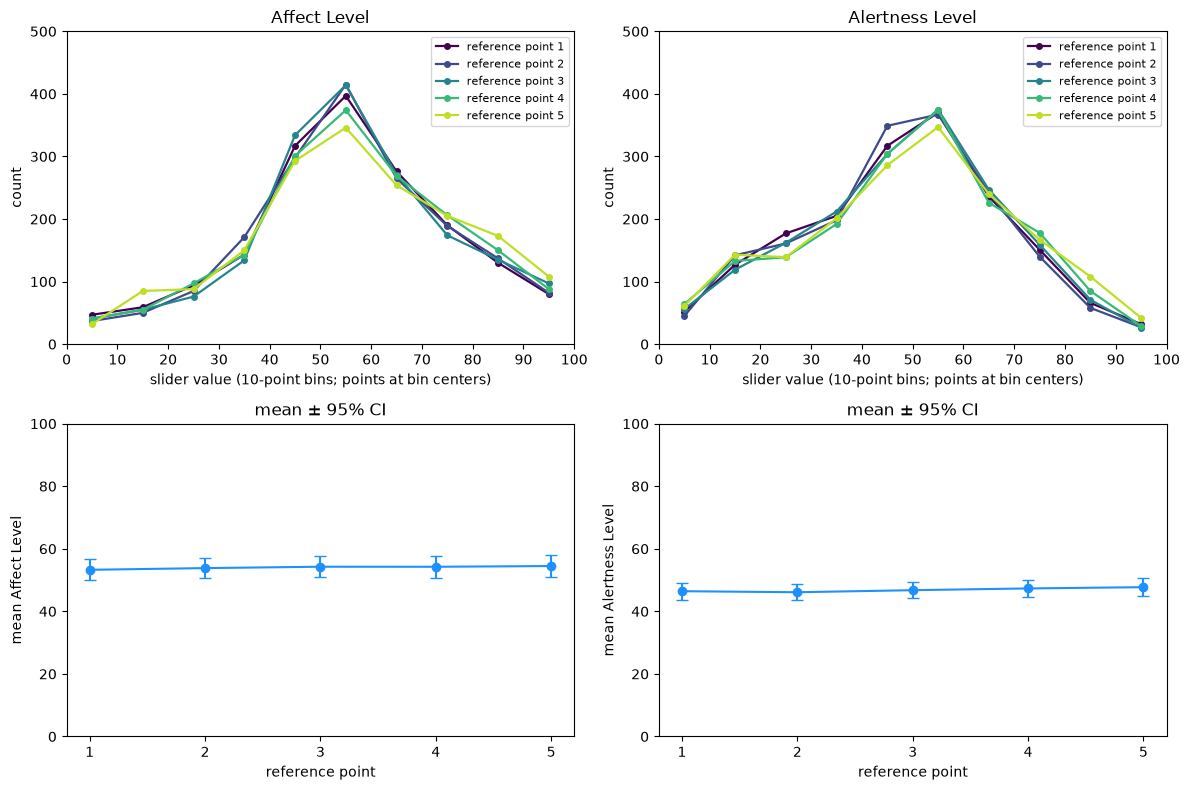

In [38]:
from matplotlib import font_manager

# 日本語フォント(使えるものを自動で選ぶ)
avail = {f.name for f in font_manager.fontManager.ttflist}
for f in ["Hiragino Sans", "Yu Gothic", "Meiryo", "Noto Sans CJK JP", "IPAexGothic"]:
    if f in avail:
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

# ref_subblock → 参照点(0〜4の順に 1,2,5,4,3)
ref_map = {0: 1, 1: 2, 2: 5, 3: 4, 4: 3}
df["ref_point"] = df["ref_subblock"].map(ref_map)
points = [1, 2, 3, 4, 5]                          # 並べたい順

cols = ["Affect Level", "Alertness Level"]
colors = plt.cm.viridis(np.linspace(0, 0.9, 5))
bins = np.arange(0, 101, 10)
mid = bins[:-1] + 5

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for k, col in enumerate(cols):
    # ---- 上段: 参照点ごとの件数の折れ線 ----
    ax = axes[0, k]
    for i, p in enumerate(points):
        x = df.loc[df["ref_point"] == p, col].dropna()
        h, _ = np.histogram(x, bins=bins)
        ax.plot(mid, h, marker="o", ms=4, lw=1.6,
                color=colors[i], label=f"reference point {p}")
    ax.set_title(col)
    ax.set_xlabel("slider value (10-point bins; points at bin centers)")
    ax.set_ylabel("count")
    ax.set_xticks(bins)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 500)
    ax.legend(fontsize=8)

    # ---- 下段: 参照点ごとの平均と95%CI(人単位)----
    ax = axes[1, k]
    pm = df.groupby(["responseId", "ref_point"])[col].mean().unstack()[points]   # 列を1〜5の順に
    m = pm.mean()
    se = pm.std(ddof=1) / np.sqrt(pm.notna().sum())
    ax.errorbar(range(5), m, yerr=1.96 * se, fmt="o-", color="#1e90ff", capsize=4)
    ax.set_xticks(range(5))
    ax.set_xticklabels(points)
    ax.set_xlabel("reference point")
    ax.set_ylabel(f"mean {col}")
    ax.set_ylim(0, 100)
    ax.set_title("mean ± 95% CI")

plt.tight_layout()
plt.show()

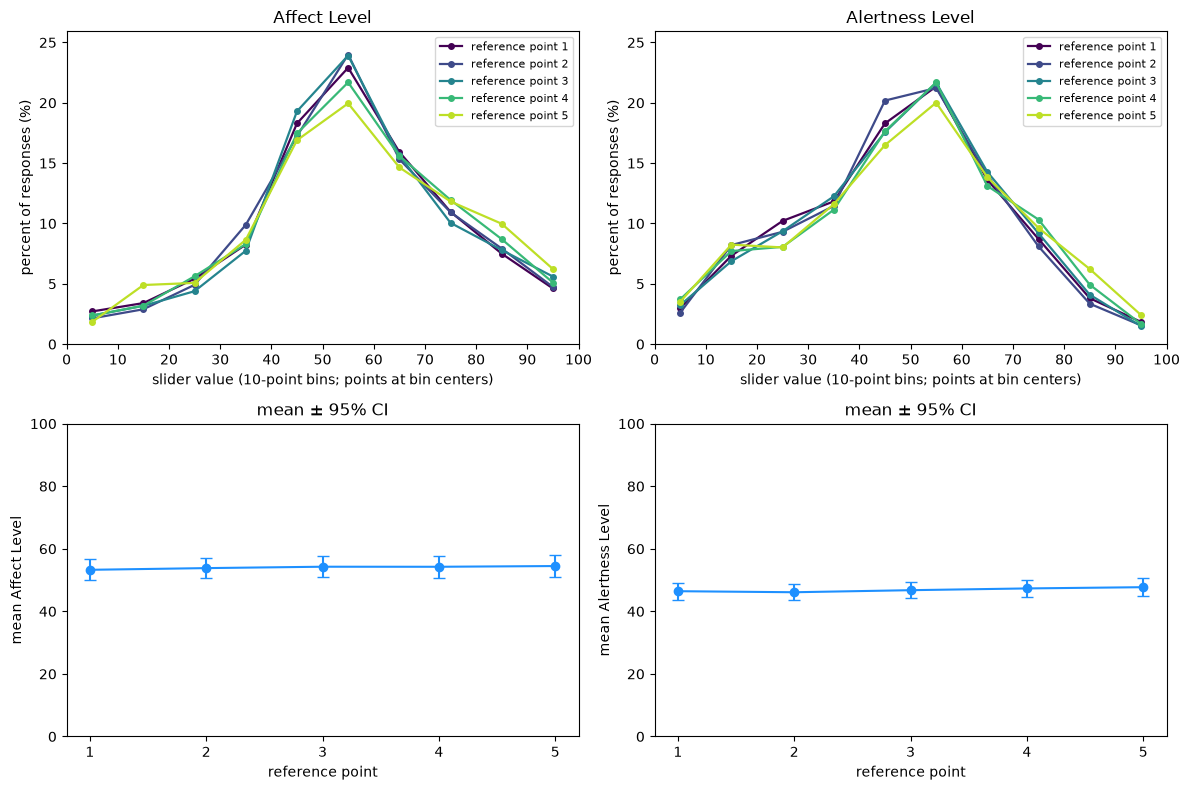

In [39]:
# 日本語フォント(使えるものを自動で選ぶ)
avail = {f.name for f in font_manager.fontManager.ttflist}
for f in ["Hiragino Sans", "Yu Gothic", "Meiryo", "Noto Sans CJK JP", "IPAexGothic"]:
    if f in avail:
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

# ref_subblock → 参照点(0〜4の順に 1,2,5,4,3)
ref_map = {0: 1, 1: 2, 2: 5, 3: 4, 4: 3}
df["ref_point"] = df["ref_subblock"].map(ref_map)
points = [1, 2, 3, 4, 5]

cols = ["Affect Level", "Alertness Level"]
colors = plt.cm.viridis(np.linspace(0, 0.9, 5))
bins = np.arange(0, 101, 10)
mid = bins[:-1] + 5

USE_RATE = True          # True: 選択率(%)、False: 選択数(件数)

# 先に全パネルの分布を計算(縦軸の上限を共通にするため)
hist = {}
for col in cols:
    for p in points:
        x = df.loc[df["ref_point"] == p, col].dropna()
        h, _ = np.histogram(x, bins=bins)
        hist[(col, p)] = h / h.sum() * 100 if USE_RATE else h
ymax = max(v.max() for v in hist.values())

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for k, col in enumerate(cols):
    # ---- 上段: 参照点ごとの選択率(または件数)の折れ線 ----
    ax = axes[0, k]
    for i, p in enumerate(points):
        ax.plot(mid, hist[(col, p)], marker="o", ms=4, lw=1.6,
                color=colors[i], label=f"reference point {p}")
    ax.set_title(col)
    ax.set_xlabel("slider value (10-point bins; points at bin centers)")
    ax.set_ylabel("percent of responses (%)" if USE_RATE else "count")
    ax.set_xticks(bins)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, ymax * 1.08)
    ax.legend(fontsize=8)

    # ---- 下段: 参照点ごとの平均と95%CI(人単位)----
    ax = axes[1, k]
    pm = df.groupby(["responseId", "ref_point"])[col].mean().unstack()[points]
    m = pm.mean()
    se = pm.std(ddof=1) / np.sqrt(pm.notna().sum())
    ax.errorbar(range(5), m, yerr=1.96 * se, fmt="o-", color="#1e90ff", capsize=4)
    ax.set_xticks(range(5))
    ax.set_xticklabels(points)
    ax.set_xlabel("reference point")
    ax.set_ylabel(f"mean {col}")
    ax.set_ylim(0, 100)
    ax.set_title("mean ± 95% CI")

plt.tight_layout()
plt.show()

#### +感情グループ別 参照点別 感情評価

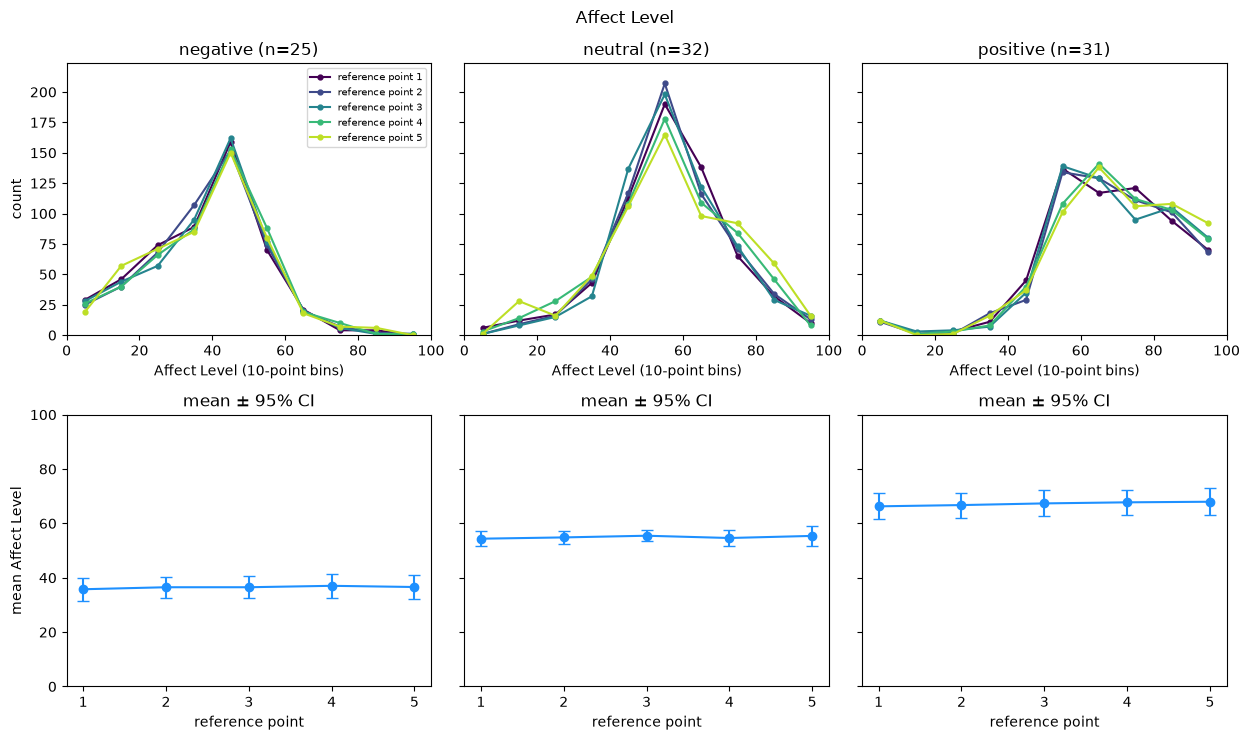

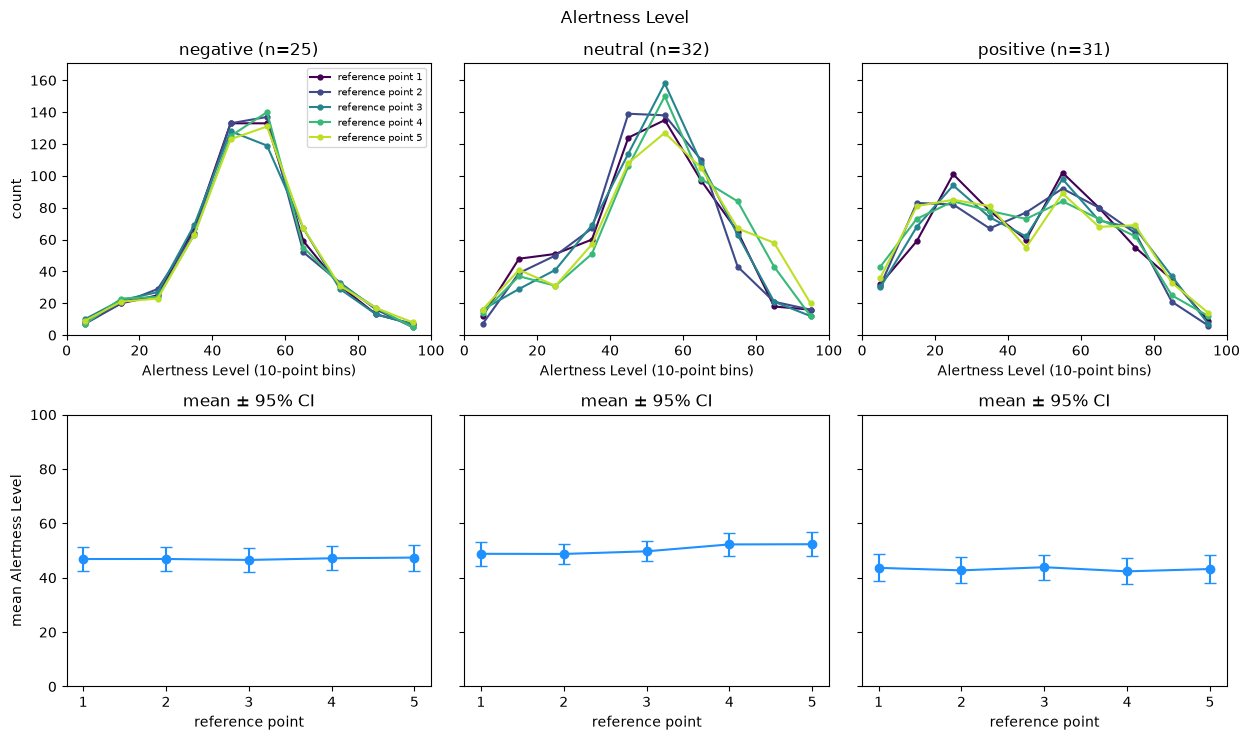

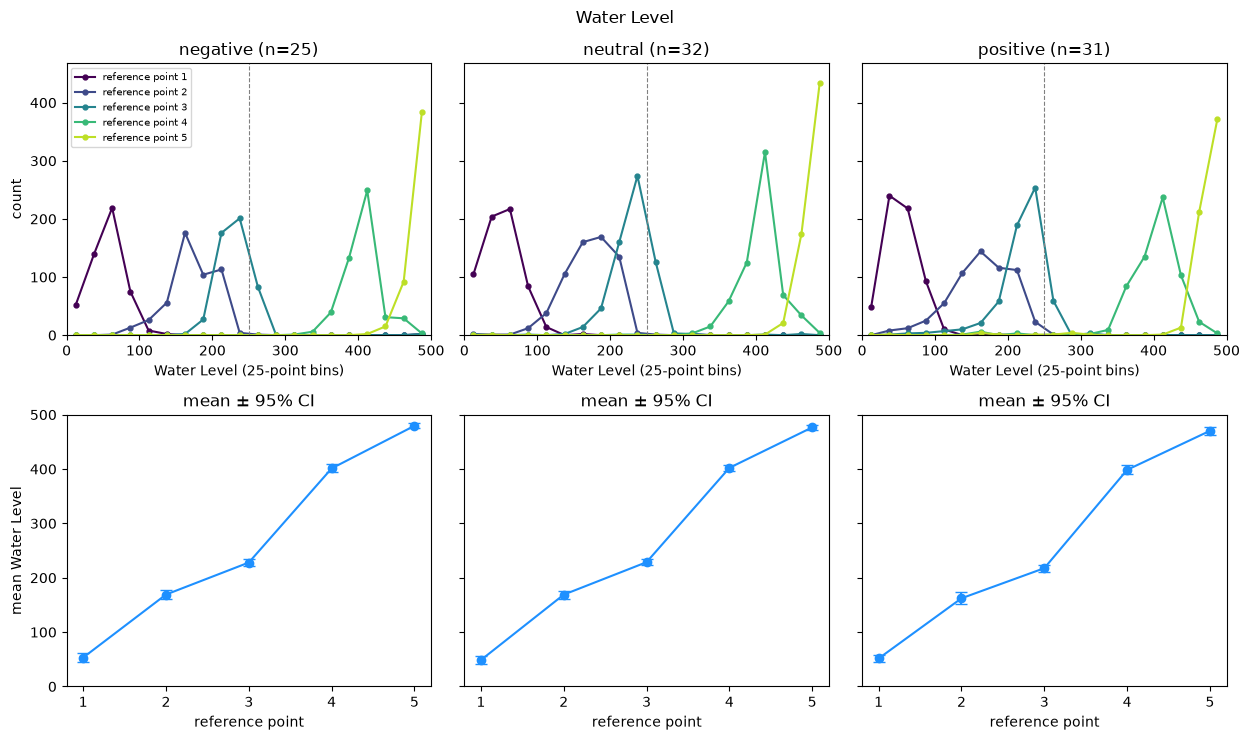

In [44]:

# 日本語フォント(使えるものを自動で選ぶ)
avail = {f.name for f in font_manager.fontManager.ttflist}
for f in ["Hiragino Sans", "Yu Gothic", "Meiryo", "Noto Sans CJK JP", "IPAexGothic"]:
    if f in avail:
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

# ref_subblock → 参照点(0〜4の順に 1,2,5,4,3)
ref_map = {0: 1, 1: 2, 2: 5, 3: 4, 4: 3}
df["ref_point"] = df["ref_subblock"].map(ref_map)
points = [1, 2, 3, 4, 5]
groups = ["negative", "neutral", "positive"]
colors = plt.cm.viridis(np.linspace(0, 0.9, 5))
n_per_group = df.groupby("Message Group")["responseId"].nunique()


def plot_by_group(col, bins, mean_ylim=(0, 100), as_percent=False, ref_line=None):
    mid = (bins[:-1] + bins[1:]) / 2
    width = bins[1] - bins[0]
    
    ymax = 0
    for g in groups:
        sub0 = df[df["Message Group"] == g]
        for p in points:
            x0 = sub0.loc[sub0["ref_point"] == p, col].dropna()
            h0, _ = np.histogram(x0, bins=bins)
            if as_percent:
                h0 = h0 / h0.sum() * 100
            ymax = max(ymax, h0.max())

    
    fig, axes = plt.subplots(2, len(groups), figsize=(4.2 * len(groups), 7.5),
                             sharex="row", sharey="row")
    for j, g in enumerate(groups):
        sub = df[df["Message Group"] == g]

        # ---- 上段: 参照点ごとの分布の折れ線 ----
        ax = axes[0, j]
        for i, p in enumerate(points):
            x = sub.loc[sub["ref_point"] == p, col].dropna()
            h, _ = np.histogram(x, bins=bins)
            if as_percent:
                h = h / h.sum() * 100
            ax.plot(mid, h, marker="o", ms=3.5, lw=1.5,
                    color=colors[i], label=f"reference point {p}")
        if ref_line is not None:
            ax.axvline(ref_line, color="gray", ls="--", lw=0.8)
        ax.set_title(f"{g} (n={n_per_group[g]})")
        ax.set_xlabel(f"{col} ({width:g}-point bins)")
        ax.set_xlim(bins[0], bins[-1])
        ax.set_ylim(0, ymax * 1.08)
        if j == 0:
            ax.set_ylabel("percent (%)" if as_percent else "count")
            ax.legend(fontsize=7)

        # ---- 下段: 参照点ごとの平均と95%CI(人単位)----
        ax = axes[1, j]
        pm = (sub.groupby(["responseId", "ref_point"])[col].mean()
                 .unstack().reindex(columns=points))
        m = pm.mean()
        se = pm.std(ddof=1) / np.sqrt(pm.notna().sum())
        ax.errorbar(range(5), m, yerr=1.96 * se, fmt="o-", color="#1e90ff", capsize=4)
        ax.set_xticks(range(5))
        ax.set_xticklabels(points)
        ax.set_xlabel("reference point")
        ax.set_ylim(*mean_ylim)
        ax.set_title("mean ± 95% CI")
        if j == 0:
            ax.set_ylabel(f"mean {col}")

    fig.suptitle(col)
    plt.tight_layout()
    plt.show()


plot_by_group("Affect Level", np.arange(0, 101, 10))
plot_by_group("Alertness Level", np.arange(0, 101, 10))
plot_by_group("Water Level", np.arange(0, 501, 25), mean_ylim=(0, 500), ref_line=250)

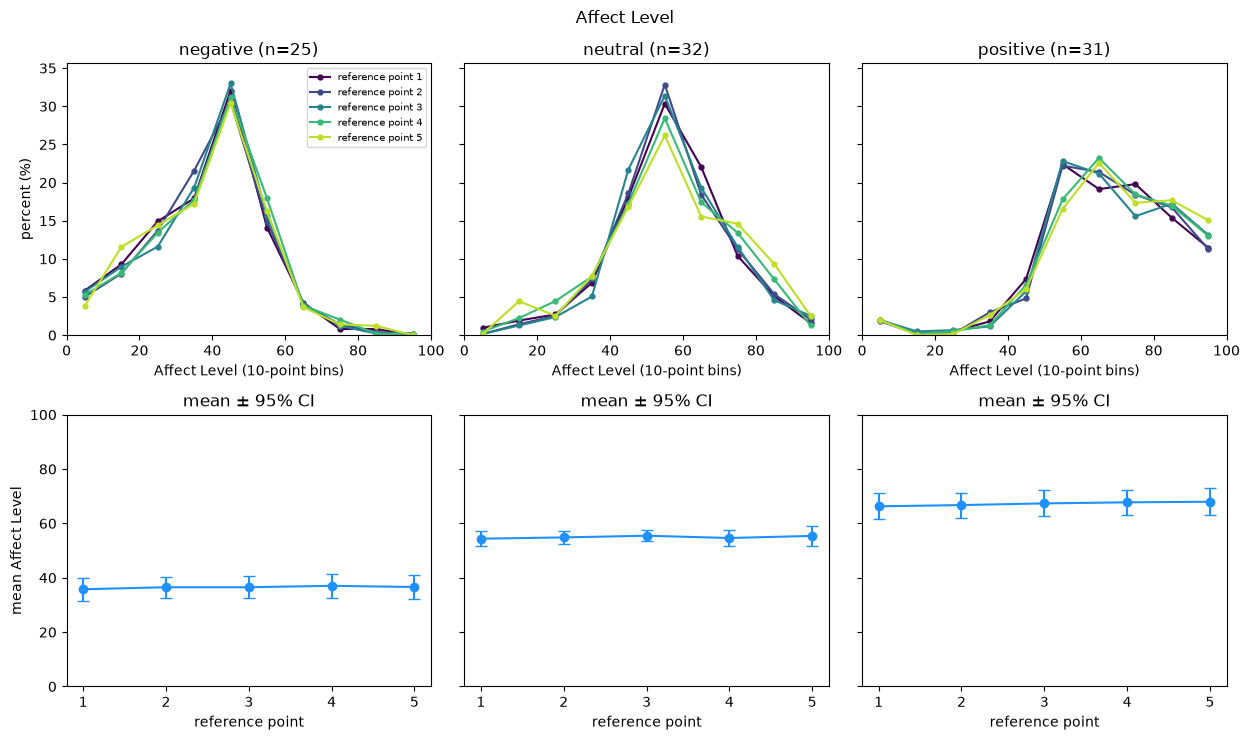

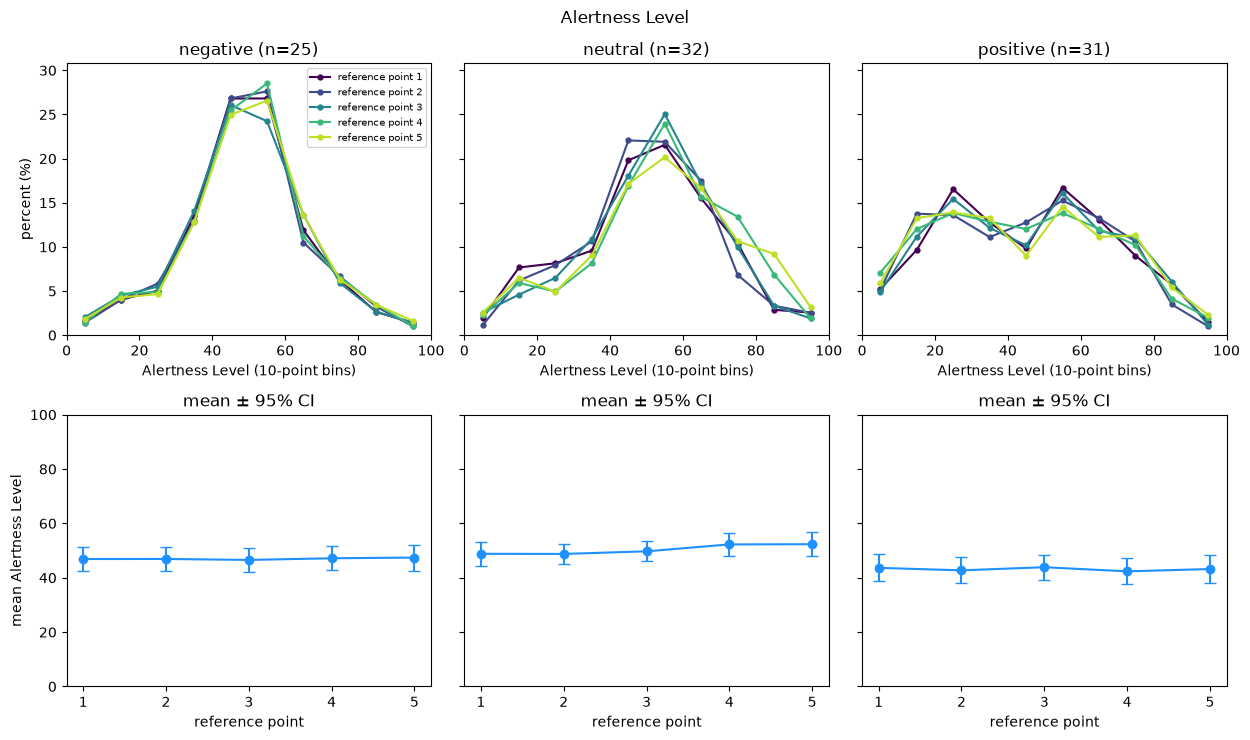

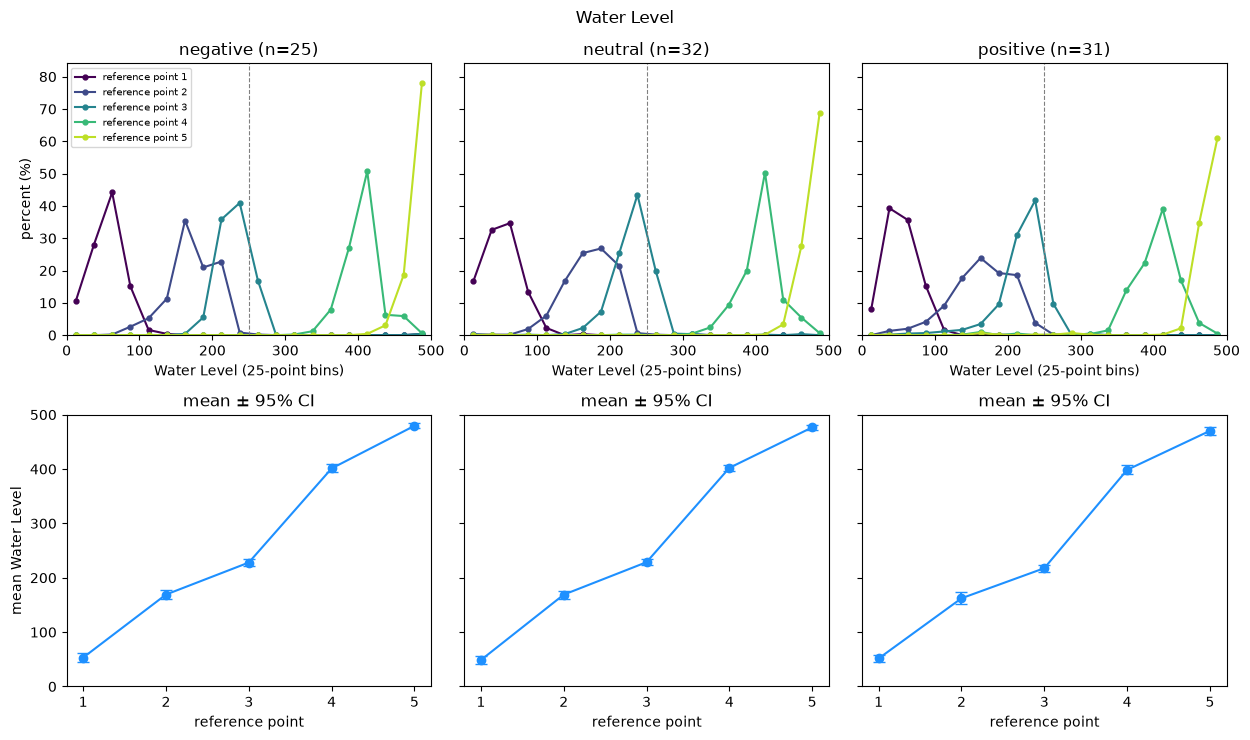

In [45]:

# 日本語フォント(使えるものを自動で選ぶ)
avail = {f.name for f in font_manager.fontManager.ttflist}
for f in ["Hiragino Sans", "Yu Gothic", "Meiryo", "Noto Sans CJK JP", "IPAexGothic"]:
    if f in avail:
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

# ref_subblock → 参照点(0〜4の順に 1,2,5,4,3)
ref_map = {0: 1, 1: 2, 2: 5, 3: 4, 4: 3}
df["ref_point"] = df["ref_subblock"].map(ref_map)
points = [1, 2, 3, 4, 5]
groups = ["negative", "neutral", "positive"]
colors = plt.cm.viridis(np.linspace(0, 0.9, 5))
n_per_group = df.groupby("Message Group")["responseId"].nunique()


def plot_by_group(col, bins, mean_ylim=(0, 100), as_percent=False, ref_line=None):
    mid = (bins[:-1] + bins[1:]) / 2
    width = bins[1] - bins[0]
    
    ymax = 0
    for g in groups:
        sub0 = df[df["Message Group"] == g]
        for p in points:
            x0 = sub0.loc[sub0["ref_point"] == p, col].dropna()
            h0, _ = np.histogram(x0, bins=bins)
            if as_percent:
                h0 = h0 / h0.sum() * 100
            ymax = max(ymax, h0.max())

    
    fig, axes = plt.subplots(2, len(groups), figsize=(4.2 * len(groups), 7.5),
                             sharex="row", sharey="row")
    for j, g in enumerate(groups):
        sub = df[df["Message Group"] == g]

        # ---- 上段: 参照点ごとの分布の折れ線 ----
        ax = axes[0, j]
        for i, p in enumerate(points):
            x = sub.loc[sub["ref_point"] == p, col].dropna()
            h, _ = np.histogram(x, bins=bins)
            if as_percent:
                h = h / h.sum() * 100
            ax.plot(mid, h, marker="o", ms=3.5, lw=1.5,
                    color=colors[i], label=f"reference point {p}")
        if ref_line is not None:
            ax.axvline(ref_line, color="gray", ls="--", lw=0.8)
        ax.set_title(f"{g} (n={n_per_group[g]})")
        ax.set_xlabel(f"{col} ({width:g}-point bins)")
        ax.set_xlim(bins[0], bins[-1])
        ax.set_ylim(0, ymax * 1.08)
        if j == 0:
            ax.set_ylabel("percent (%)" if as_percent else "count")
            ax.legend(fontsize=7)

        # ---- 下段: 参照点ごとの平均と95%CI(人単位)----
        ax = axes[1, j]
        pm = (sub.groupby(["responseId", "ref_point"])[col].mean()
                 .unstack().reindex(columns=points))
        m = pm.mean()
        se = pm.std(ddof=1) / np.sqrt(pm.notna().sum())
        ax.errorbar(range(5), m, yerr=1.96 * se, fmt="o-", color="#1e90ff", capsize=4)
        ax.set_xticks(range(5))
        ax.set_xticklabels(points)
        ax.set_xlabel("reference point")
        ax.set_ylim(*mean_ylim)
        ax.set_title("mean ± 95% CI")
        if j == 0:
            ax.set_ylabel(f"mean {col}")

    fig.suptitle(col)
    plt.tight_layout()
    plt.show()


plot_by_group("Affect Level", np.arange(0, 101, 10), as_percent=True)
plot_by_group("Alertness Level", np.arange(0, 101, 10), as_percent=True)
plot_by_group("Water Level", np.arange(0, 501, 25), mean_ylim=(0, 500), ref_line=250, as_percent=True)

#### 感情グループ別 参照点別 記述統計量

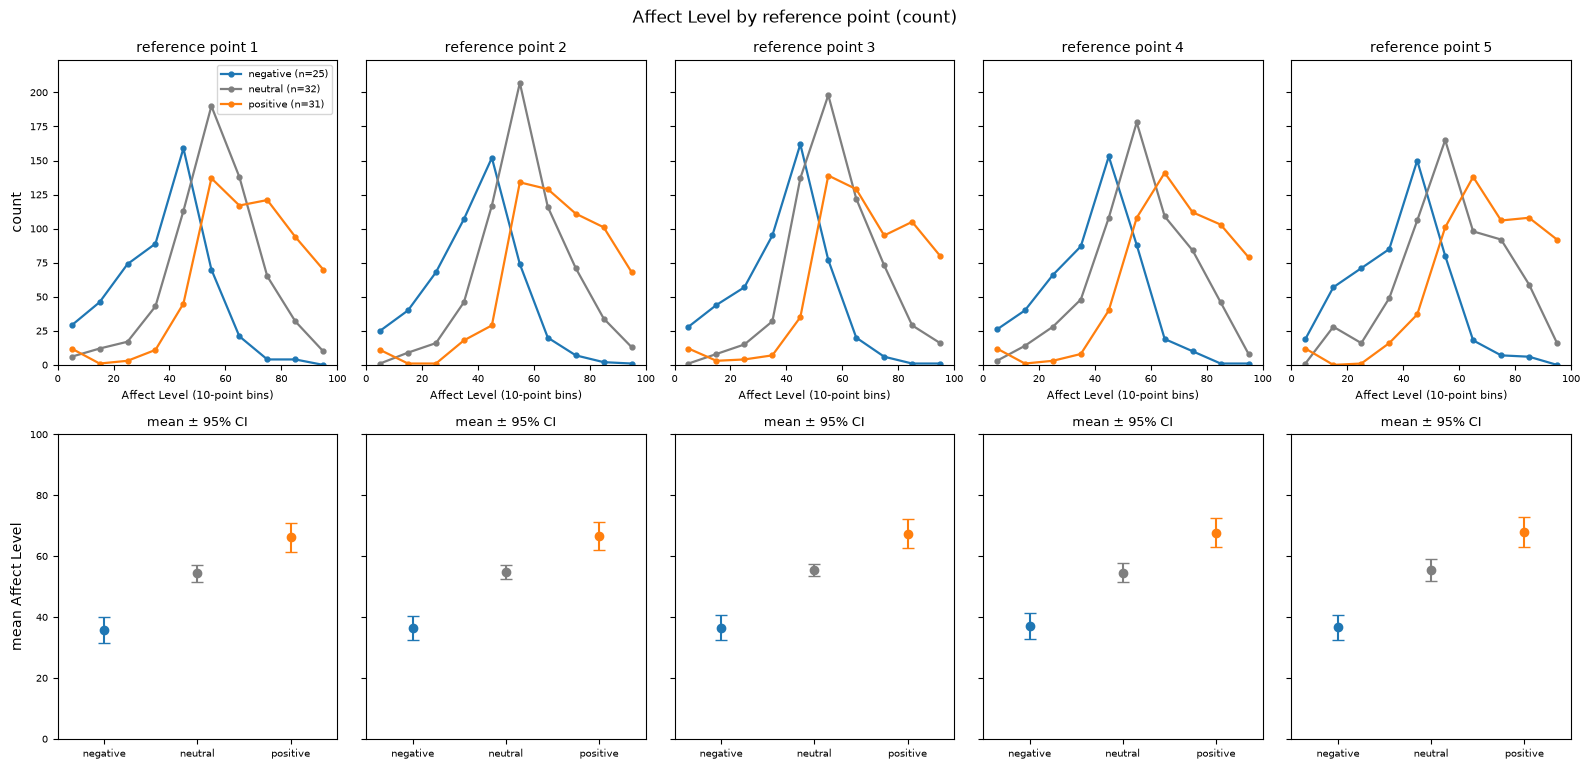

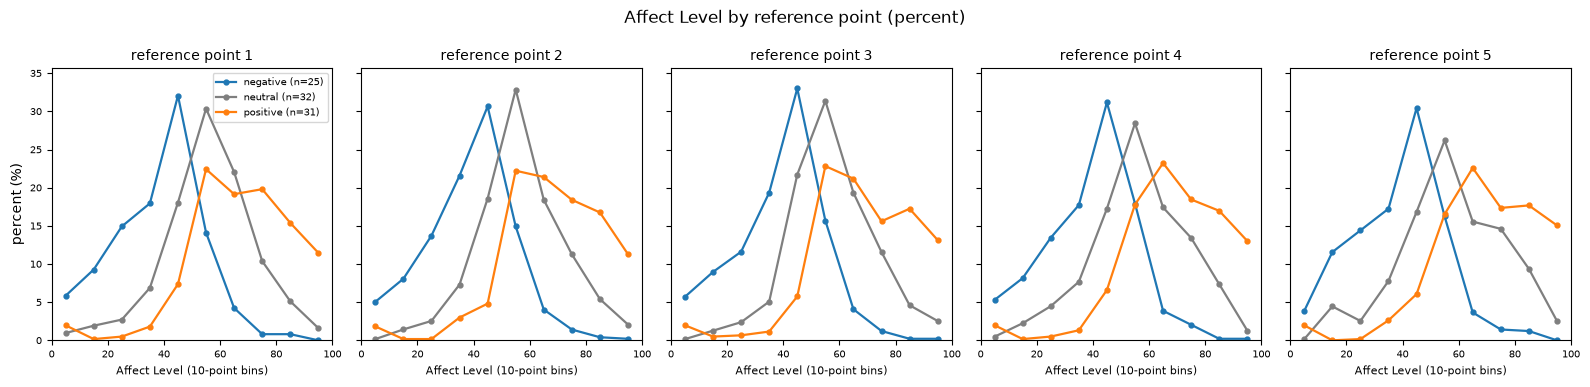

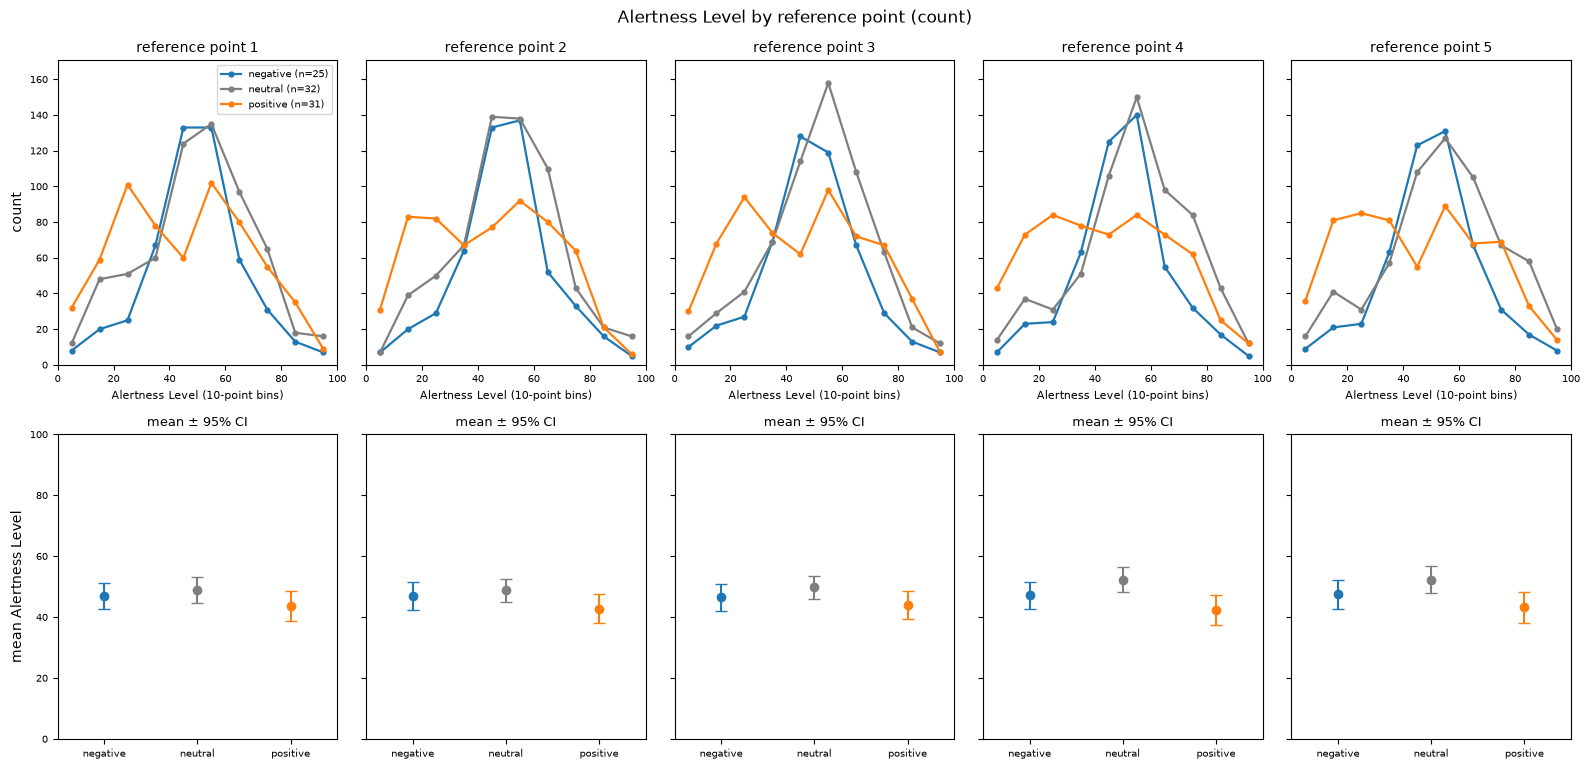

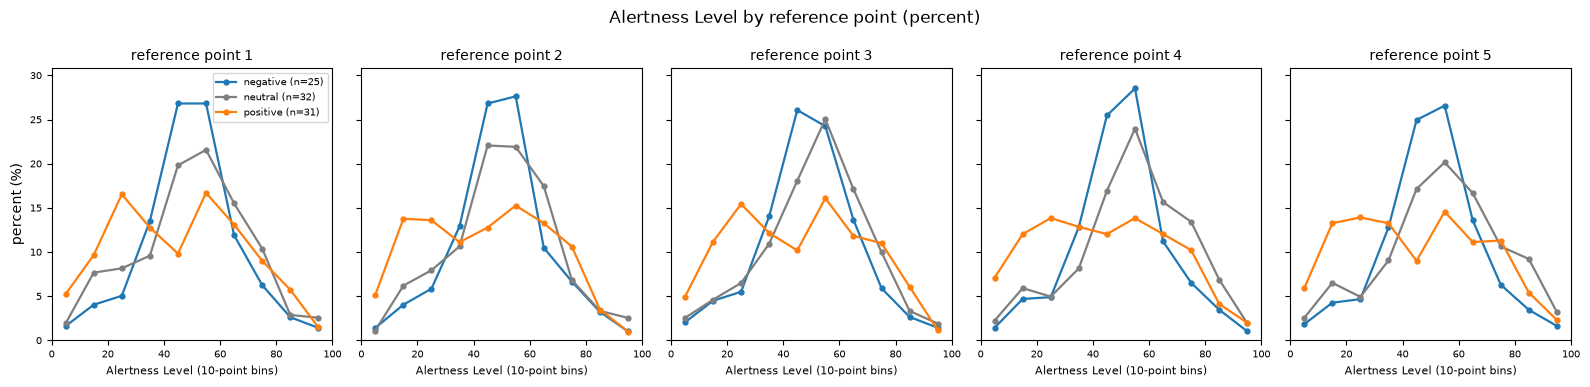

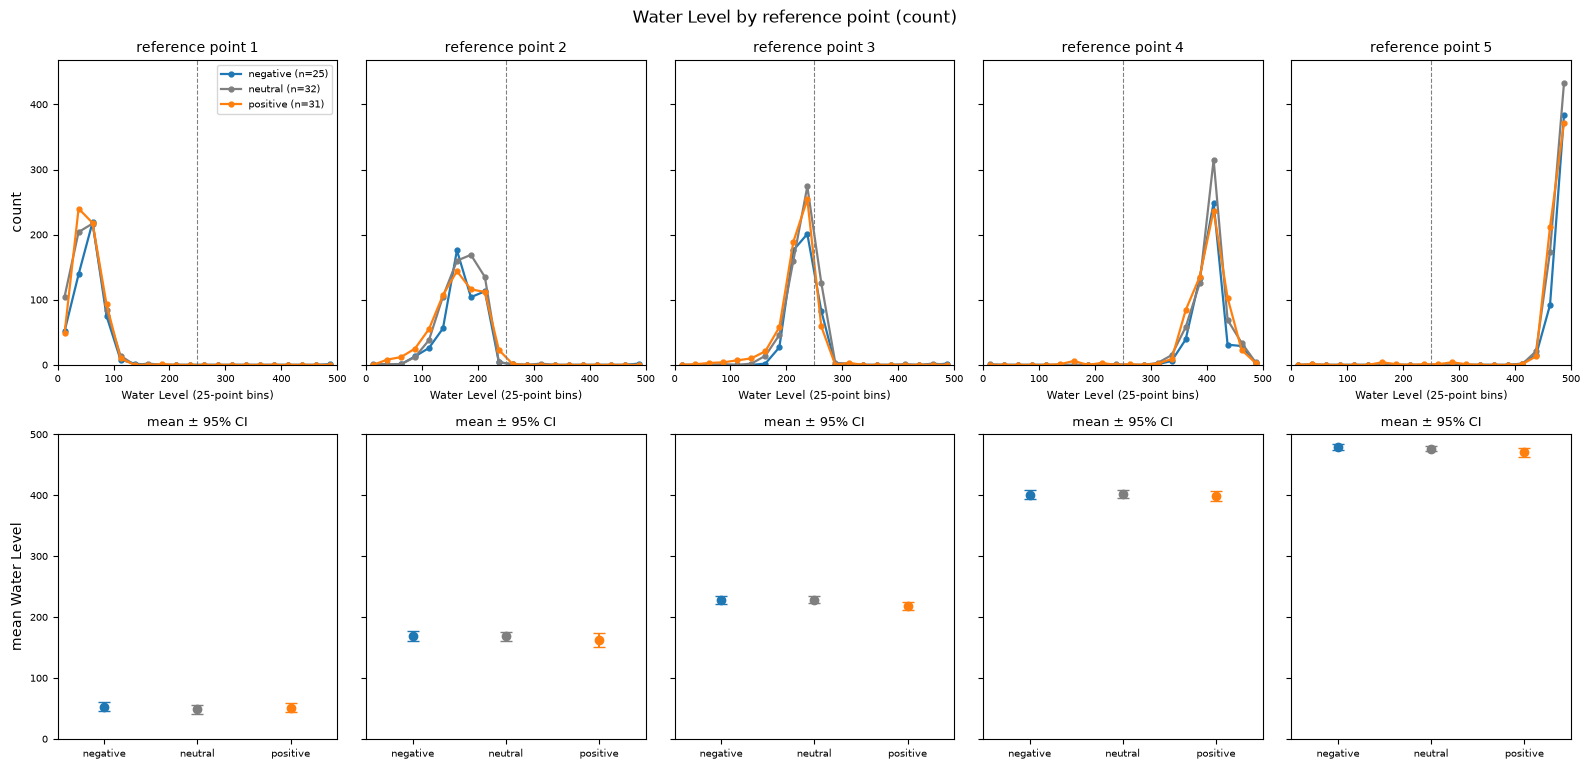

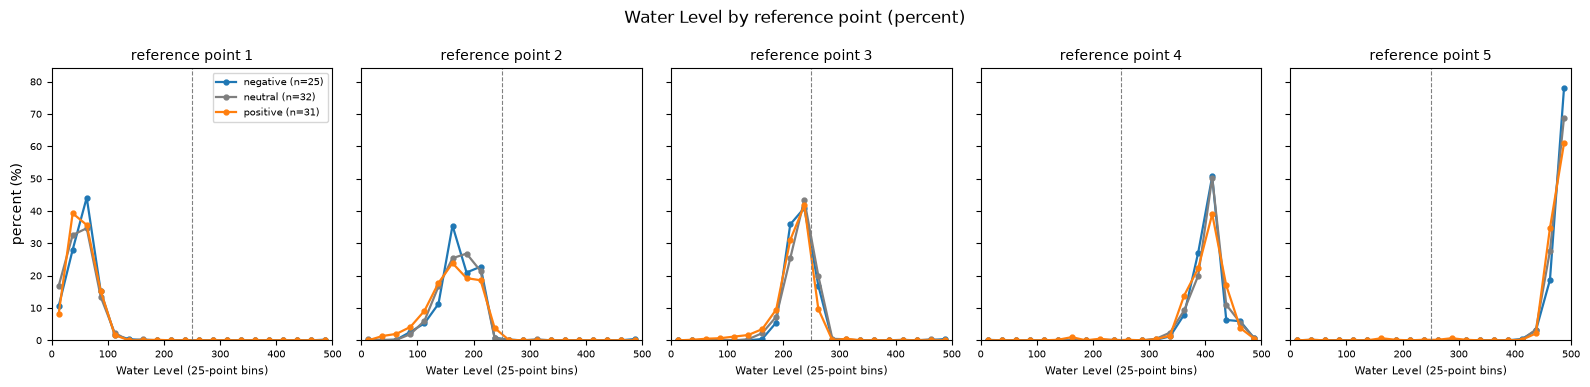

In [46]:
ref_map = {0: 1, 1: 2, 2: 5, 3: 4, 4: 3}                  # ref_subblock → 参照点
df["ref_point"] = df["ref_subblock"].map(ref_map)
points = [1, 2, 3, 4, 5]
groups = ["negative", "neutral", "positive"]
gcolor = {"negative": "#1f77b4", "neutral": "#7f7f7f", "positive": "#ff7f0e"}
n_per_group = df.groupby("Message Group")["responseId"].nunique()


def plot_by_point(col, bins, mean_ylim=(0, 100), as_percent=False,
                  ref_line=None, show_mean=True):
    mid = (bins[:-1] + bins[1:]) / 2
    width = bins[1] - bins[0]

    # 先に全パネルの分布を計算(縦軸の上限をそろえるため)
    hist = {}
    for g in groups:
        for p in points:
            x = df.loc[(df["Message Group"] == g) & (df["ref_point"] == p), col].dropna()
            h, _ = np.histogram(x, bins=bins)
            hist[(g, p)] = h / h.sum() * 100 if as_percent else h   # 割合は、各群・各参照点で合計100%
    ymax = max(v.max() for v in hist.values())

    nrows = 2 if show_mean else 1
    fig, axes = plt.subplots(nrows, 5, figsize=(16, 3.9 * nrows),
                             sharex="row", sharey="row", squeeze=False)

    # ---- 上段: 参照点ごとの分布(3群を重ねる)----
    for c, p in enumerate(points):
        ax = axes[0, c]
        for g in groups:
            ax.plot(mid, hist[(g, p)], marker="o", ms=3.5, lw=1.6, color=gcolor[g],
                    label=f"{g} (n={n_per_group[g]})")
        if ref_line is not None:
            ax.axvline(ref_line, color="gray", ls="--", lw=0.8)
        ax.set_title(f"reference point {p}", fontsize=10)
        ax.set_xlabel(f"{col} ({width:g}-point bins)", fontsize=8)
        ax.set_xlim(bins[0], bins[-1])
        ax.set_ylim(0, ymax * 1.08)
        ax.tick_params(labelsize=7)
    axes[0, 0].set_ylabel("percent (%)" if as_percent else "count")
    axes[0, 0].legend(fontsize=7)

    # ---- 下段: 参照点ごとの平均と95%CI(人単位、3群を並べる)----
    if show_mean:
        pmean = df.groupby(["responseId", "ref_point"])[col].mean().unstack()
        grp = df.groupby("responseId")["Message Group"].first()
        for c, p in enumerate(points):
            ax = axes[1, c]
            for j, g in enumerate(groups):
                v = pmean.loc[grp[grp == g].index, p].dropna()
                m, se = v.mean(), v.std(ddof=1) / np.sqrt(len(v))
                ax.errorbar(j, m, yerr=1.96 * se, fmt="o", color=gcolor[g], capsize=4)
            ax.set_xticks(range(3))
            ax.set_xticklabels(groups, fontsize=7)
            ax.set_xlim(-0.5, 2.5)
            ax.set_ylim(*mean_ylim)
            ax.set_title("mean ± 95% CI", fontsize=9)
            ax.tick_params(labelsize=7)
        axes[1, 0].set_ylabel(f"mean {col}")

    fig.suptitle(f"{col} by reference point" + (" (percent)" if as_percent else " (count)"))
    plt.tight_layout()
    plt.show()


specs = [
    ("Affect Level",    np.arange(0, 101, 10), (0, 100), None),
    ("Alertness Level", np.arange(0, 101, 10), (0, 100), None),
    ("Water Level",     np.arange(0, 501, 25), (0, 500), 250),
]
for col, bins, mylim, rl in specs:
    plot_by_point(col, bins, mylim, as_percent=False, ref_line=rl)                    # 件数版
    plot_by_point(col, bins, mylim, as_percent=True, ref_line=rl, show_mean=False)    # 割合版

#### 参照点別 waterlevel 記述統計量

In [48]:
cols = ["Water Level"]

# 1. 参照点ごとの有効回答数(NaN は除く)
print(df.groupby("ref_subblock")[cols].count())

# 2. 記述統計
print(df.groupby("ref_subblock")[cols].agg(["count", "mean", "std", "median"]).round(2))

# 3. 値ごとの選択数(10刻みにまとめた表)
print(df[cols].describe())                    # 値の範囲を先に確認(0〜100か)
bins = np.arange(0, 101, 10)
for col in cols:
    binned = pd.cut(df[col], bins=bins, include_lowest=True)
    print(f"\n{col}")
    print(pd.crosstab(binned, df["ref_subblock"]))

              Water Level
ref_subblock             
0                    1733
1                    1729
2                    1734
3                    1724
4                    1731
             Water Level                      
                   count    mean    std median
ref_subblock                                  
0                   1733   50.98  24.91   50.0
1                   1729  166.55  37.11  170.0
2                   1734  475.16  28.94  480.0
3                   1724  400.51  33.53  400.0
4                   1731  224.56  29.50  230.0
       Water Level
count  8651.000000
mean    263.486996
std     157.853813
min       2.000000
25%     145.000000
50%     230.000000
75%     416.000000
max     500.000000

Water Level
ref_subblock      0   1  2  3  4
Water Level                     
(-0.001, 10.0]   21   0  0  0  0
(10.0, 20.0]    136   0  0  1  0
(20.0, 30.0]    186   4  0  0  0
(30.0, 40.0]    223   4  1  0  0
(40.0, 50.0]    468   4  1  0  1
(50.0, 60.0]    223   2  0 

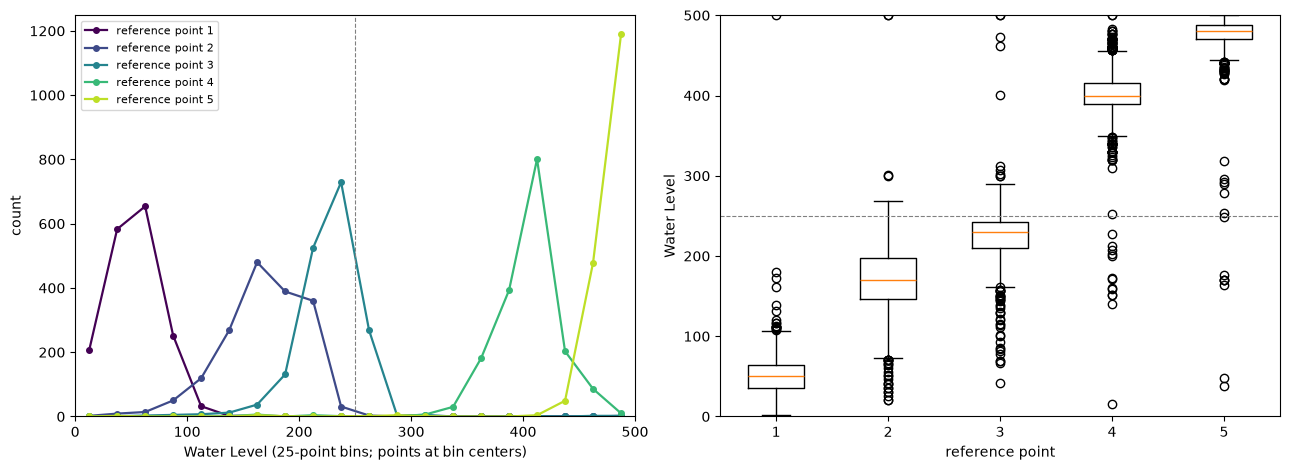

            count   mean   std   min    25%    50%    75%    max
ref_point                                                       
1          1733.0   51.0  24.9   2.0   35.0   50.0   64.0  500.0
2          1729.0  166.5  37.1  21.0  147.0  170.0  197.0  500.0
3          1731.0  224.6  29.5  42.0  210.0  230.0  242.0  500.0
4          1724.0  400.5  33.5  15.0  389.0  400.0  416.0  500.0
5          1734.0  475.2  28.9  38.0  470.0  480.0  488.0  500.0


In [47]:
col = "Water Level"
ref_map = {0: 1, 1: 2, 2: 5, 3: 4, 4: 3}
df["ref_point"] = df["ref_subblock"].map(ref_map)
points = [1, 2, 3, 4, 5]

colors = plt.cm.viridis(np.linspace(0, 0.9, 5))
bins = np.arange(0, 501, 25)                 # 0〜500を25刻み
mid = bins[:-1] + 12.5

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# ---- 左: 参照点ごとの件数の折れ線 ----
ax = axes[0]
for i, p in enumerate(points):
    x = df.loc[df["ref_point"] == p, col].dropna()
    h, _ = np.histogram(x, bins=bins)
    ax.plot(mid, h, marker="o", ms=4, lw=1.6, color=colors[i], label=f"reference point {p}")
ax.axvline(250, color="gray", ls="--", lw=0.8)            # 半分(250)の目安線
ax.set_xlabel("Water Level (25-point bins; points at bin centers)")
ax.set_ylabel("count")
ax.set_xlim(0, 500)
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)

# ---- 右: 参照点ごとの箱ひげ図 ----
ax = axes[1]
data = [df.loc[df["ref_point"] == p, col].dropna() for p in points]
ax.boxplot(data, showfliers=True)
ax.set_xticklabels(points)
ax.axhline(250, color="gray", ls="--", lw=0.8)
ax.set_xlabel("reference point")
ax.set_ylabel(col)
ax.set_ylim(0, 500)

plt.tight_layout()
plt.show()

# 参照点ごとの要約
print(df.groupby("ref_point")[col].describe().round(1))